## **Exploratory Data Analysis (EDA)**

We are now performing a quantitative and statistical analysis of the EBSD data. This process will help us understand the dataset's characteristics, identify any potential issues, and prepare for the feature engineering stage of our machine learning project.


### **Setup and Data Loading**

We'll start by importing the necessary libraries and defining a function to load our data, as we did in the previous plotting script. This ensures our data is correctly parsed and ready for analysis.


In [2]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.transform import Rotation as R

In [3]:
def load_ebsd_data(file_path):
    try:
        with open(file_path, 'r') as file:
            lines = file.readlines()

        header_info = {line.split(":")[0].strip().replace('# ', ''): line.split(":")[1].strip() for line in lines if line.startswith("# ") and ":" in line and not line.startswith('# COLUMN')}
        
        NCOLS_ODD = int(header_info.get('NCOLS_ODD', 0))
        NCOLS_EVEN = int(header_info.get('NCOLS_EVEN', 0))
        NROWS = int(header_info.get('NROWS', 0))

        header_end_index = None
        column_headers_line = None
        for i, line in enumerate(lines):
            if line.strip() == "# HEADER: End":
                header_end_index = i
            if line.startswith("# COLUMN_HEADERS:"):
                column_headers_line = line
        
        if header_end_index is None or column_headers_line is None:
            raise ValueError("Could not find required header information.")

        column_headers = column_headers_line.split(":")[1].strip().split(",")
        column_headers = [header.strip() for header in column_headers]

        data_string = "".join(lines[header_end_index+1:])
        df = pd.read_csv(io.StringIO(data_string), sep='\s+', names=column_headers)
        
        return df, NCOLS_ODD, NCOLS_EVEN, NROWS

    except FileNotFoundError:
        print(f"Error: The file '{file_path}' was not found.")
        return None, None, None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None, None, None

file_path = "Hmg_NI-1000pts_txt.txt"
df, NCOLS_ODD, NCOLS_EVEN, NROWS = load_ebsd_data(file_path)

if df is not None:
    print("Data loaded successfully.")

Data loaded successfully.



### **Data Quality and Statistical Summary**

Before we plot anything, it's essential to get a statistical overview of the data. We will check for missing values and view descriptive statistics like the mean, standard deviation, and quartiles for all numerical columns.


In [4]:
if df is not None:
    print("Statistical Summary of Numerical Columns:")
    print(df.describe().T)

    print("\nData Types and Missing Values:")
    df.info()

Statistical Summary of Numerical Columns:
                       count         mean          std      min          25%  \
phi1                 84753.0     3.233911     1.856317  0.00019     2.110760   
PHI                  84753.0     1.676241     0.796057  0.09021     1.005010   
phi2                 84753.0     2.751511     2.016042  0.00009     0.667040   
x                    84753.0   166.800000    96.418563  0.00000    83.200000   
y                    84753.0    69.974851    40.599986  0.00000    34.641010   
IQ                   84753.0  3264.318870  1022.406727  0.00000  2973.400000   
CI                   84753.0     0.653887     0.261060 -1.00000     0.625000   
Phase index          84753.0     1.084257     0.279341  0.00000     1.000000   
SEM                  84753.0  8268.794096  1760.615060  0.00000  7068.000000   
Fit                  84753.0     1.023584     4.002900  0.00000     0.692000   
PRIAS Bottom Strip   84753.0    85.001225    16.349108  0.00000    82.779800  

### **Data Distribution Analysis**

We are plotting histograms for key features to understand their distribution. A `seaborn` histogram with a kernel density estimate (`kde`) overlay helps us see the shape of the data, which is useful for identifying outliers or understanding the spread of values like `IQ` and `CI`.


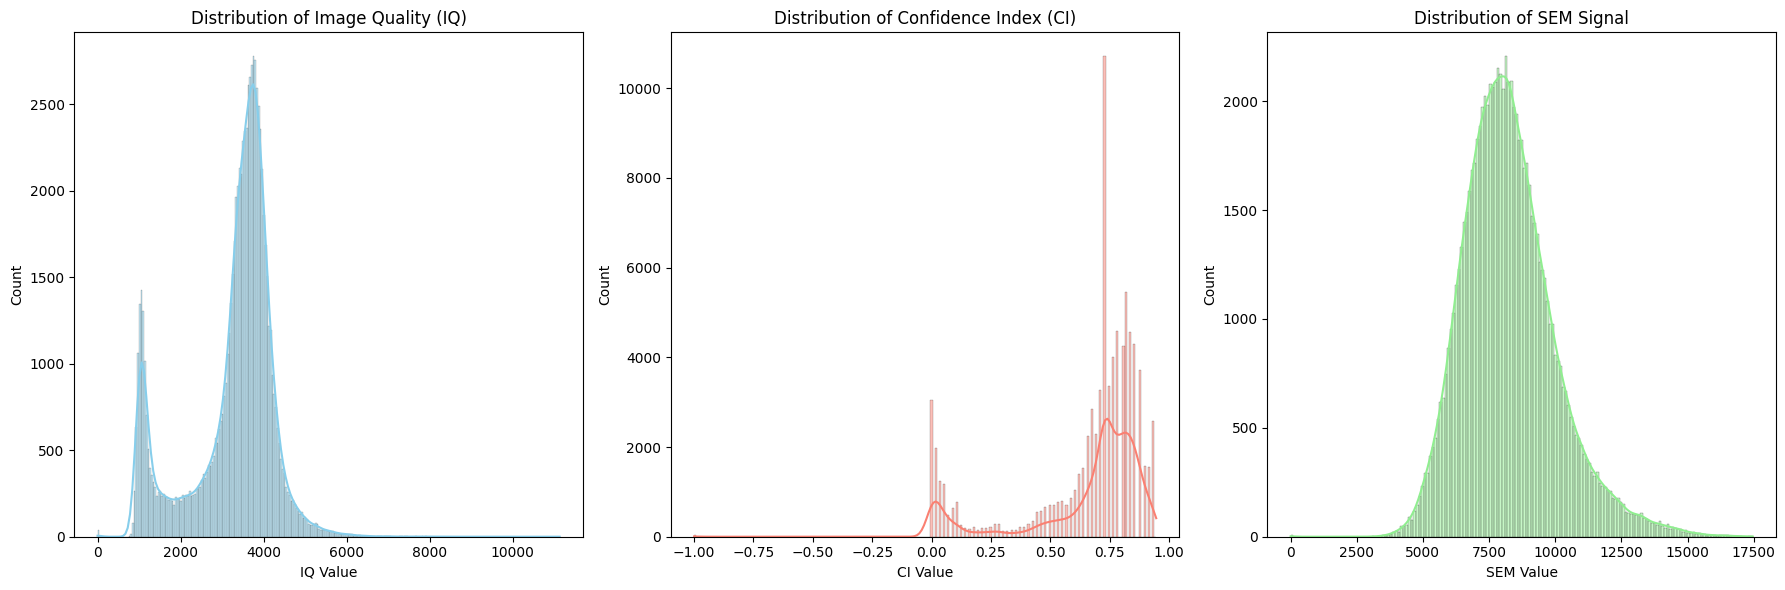

In [5]:
if df is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    sns.histplot(df['IQ'], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title('Distribution of Image Quality (IQ)')
    axes[0].set_xlabel('IQ Value')
    
    sns.histplot(df['CI'], kde=True, ax=axes[1], color='salmon')
    axes[1].set_title('Distribution of Confidence Index (CI)')
    axes[1].set_xlabel('CI Value')
    
    sns.histplot(df['SEM'], kde=True, ax=axes[2], color='lightgreen')
    axes[2].set_title('Distribution of SEM Signal')
    axes[2].set_xlabel('SEM Value')
    
    plt.tight_layout()
    plt.show()

### **Correlation Analysis**

We are visualizing the correlation matrix of our key numerical features using a heatmap. This plot is essential for understanding the linear relationships between variables, for example, how `IQ` correlates with `CI`, or if there's any relationship between the Euler angles.


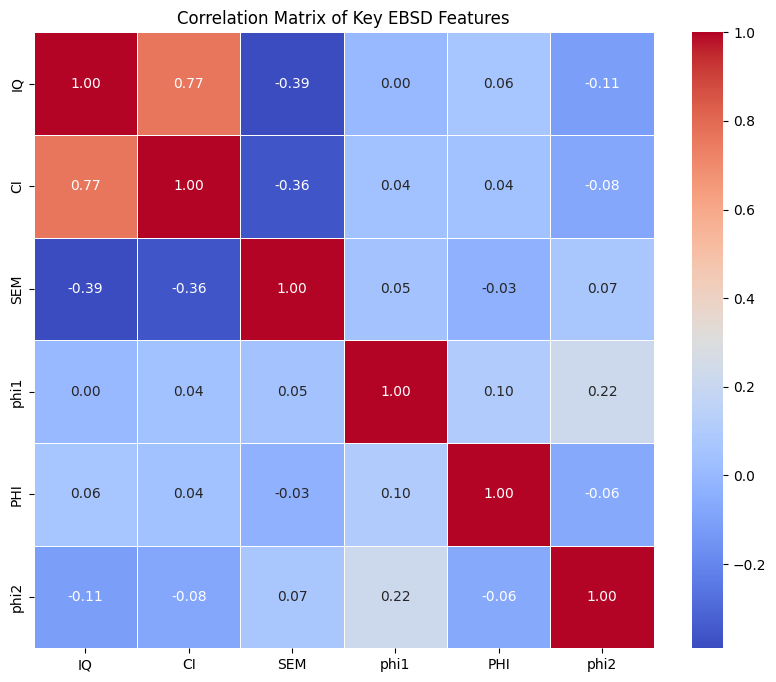

In [6]:
if df is not None:
    correlation_cols = ['IQ', 'CI', 'SEM', 'phi1', 'PHI', 'phi2']
    corr_matrix = df[correlation_cols].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Matrix of Key EBSD Features')
    plt.show()


### **Phase-Specific Analysis**

We are now performing a phase-specific analysis to compare the properties of our two materials: Iron Gamma (Phase 1) and Iron Epsilon (Phase 2). This helps us understand if there are significant differences in data quality or signal between the two phases.


Phase 1 (Iron Gamma) has 77538 data points.
Phase 2 (Iron Epsilon) has 7178 data points.


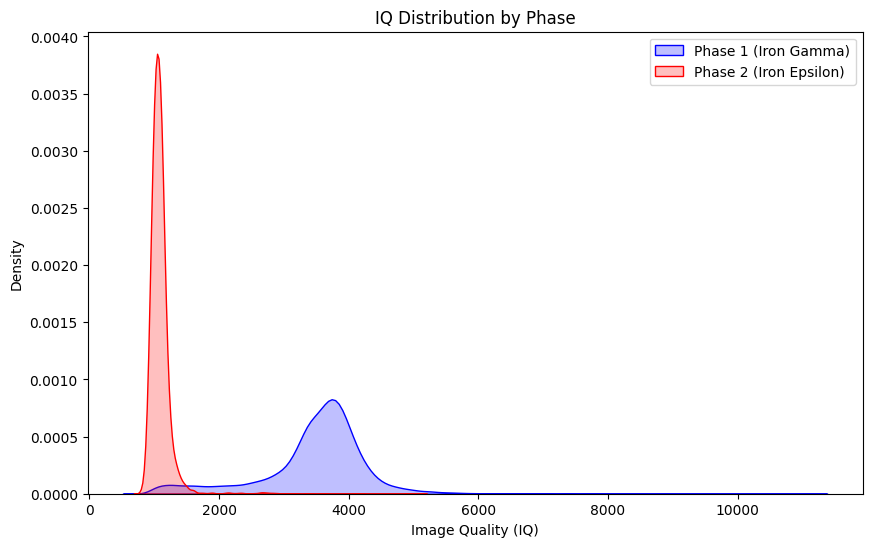

In [7]:
if df is not None:
    phase_1_data = df[df['Phase index'] == 1]
    phase_2_data = df[df['Phase index'] == 2]

    print(f"Phase 1 (Iron Gamma) has {len(phase_1_data)} data points.")
    print(f"Phase 2 (Iron Epsilon) has {len(phase_2_data)} data points.")

    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=phase_1_data, x='IQ', label='Phase 1 (Iron Gamma)', color='blue', fill=True)
    sns.kdeplot(data=phase_2_data, x='IQ', label='Phase 2 (Iron Epsilon)', color='red', fill=True)
    plt.title('IQ Distribution by Phase')
    plt.xlabel('Image Quality (IQ)')
    plt.ylabel('Density')
    plt.legend()
    plt.show()
